# 01 - Data Cleansing & Storage Benchmark
**Project:** E-Commerce & Retail Analytics - Milestone 1

Notebook ini mengeksekusi dua tahap:

1. **Veracity check & Data Cleansing** pada 3 dataset hasil `synthetic_generator.py`
   (`transactions.csv`, `customers.csv`, `clickstream.json`).
2. **Storage benchmark** format file **CSV vs JSONL vs Parquet** (ukuran file, kecepatan tulis, kecepatan baca,
   dan kecepatan query agregasi).

Alur: `data/raw` -> *profiling kekotoran* -> *cleansing* -> *validasi* -> `data/clean` -> *benchmark* -> `data/benchmark`.

In [1]:
import gc
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

RAW, CLEAN, BENCH = Path("../data/raw"), Path("../data/clean"), Path("../data/benchmark")
for p in (CLEAN, BENCH):
    p.mkdir(parents=True, exist_ok=True)

NOW = pd.Timestamp.now()   # batas "masa depan" untuk validasi tanggal
print("pandas", pd.__version__, "| acuan waktu:", NOW.strftime("%Y-%m-%d %H:%M"))

pandas 3.0.5 | acuan waktu: 2026-11-04 19:47


## 1. Load data mentah & cek volume

In [2]:
t0 = time.perf_counter()
trx_raw  = pd.read_csv(RAW / "transactions.csv")
cust_raw = pd.read_csv(RAW / "customers.csv")
clk_raw  = pd.read_json(RAW / "clickstream.json", lines=True, dtype=False, convert_dates=False)
print(f"Data termuat dalam {time.perf_counter() - t0:.1f} detik")

volume = pd.DataFrame([
    ("transactions.csv (Fact)",   len(trx_raw),  1_000_000),
    ("customers.csv (Dimension)", len(cust_raw), 50_000),
    ("clickstream.json (JSONL)",  len(clk_raw),  200_000),
], columns=["dataset", "rows", "minimum_required"])
volume["memenuhi_syarat"] = volume["rows"] >= volume["minimum_required"]
display(volume)

display(trx_raw.head(3)); display(cust_raw.head(3)); display(clk_raw.head(3))

Data termuat dalam 5.2 detik


,dataset,rows,minimum_required,memenuhi_syarat
0,transactions.csv (Fact),1524000,1000000,True
1,customers.csv (Dimension),75600,50000,True
2,clickstream.json (JSONL),303600,200000,True


,transaction_id,customer_id,timestamp,product_id,category,quantity,price,discount,payment_method,city
0,T000359132,C0026297,2025-12-09 06:57:11,P01832,Fashion,1,191500.0,0.15,Debit Card,Yogyakarta
1,T001053752,C0033786,2025-06-11 18:06:00,P00725,Electronics,2,1306200.0,0.05,E-Wallet,Bekasi
2,T001331524,C0010927,2025-06-21 17:59:51,P01203,Fashion,1,409900.0,0.00,Credit Card,Medan


,customer_id,age_group,gender,signup_date,membership_tier,city
0,C0061380,25-34,Male,2024-06-04,Silver,Semarang
1,C0026977,25-34,Female,2022-11-14,Silver,Tangerang
2,C0073656,55+,Male,2022-12-08,Silver,Bandung


,event_id,session_id,user_id,timestamp,page_url,action_event,device_type
0,E00139117,S0026999,C0032661,2024-05-29T10:41:00,/category,filter,mobile
1,E00201981,S0033550,C0038074,2024-12-03T23:07:41,/product,page_view,desktop
2,E00066577,S0006605,C0020421,2025-11-08T06:34:06,/account,login,mobile


## 2. Veracity check - profiling data kotor
Setiap jenis anomali dihitung dari data mentah **tanpa melihat log generator**, lalu dibandingkan dengan
`injection_log.json` untuk memastikan deteksi kita konsisten dengan yang diinjeksikan.
Target ketentuan: total baris kotor **5% - 10%** per dataset.

In [3]:
CANON_CITIES = {"Jakarta", "Bandung", "Surabaya", "Medan", "Semarang",
                "Yogyakarta", "Makassar", "Denpasar", "Tangerang", "Bekasi"}
CANON_GENDER = {"Male", "Female"}
CANON_DEVICE = {"mobile", "desktop", "tablet"}

ts_trx  = pd.to_datetime(trx_raw["timestamp"],  errors="coerce")
sd_cust = pd.to_datetime(cust_raw["signup_date"], errors="coerce")
ts_clk  = pd.to_datetime(clk_raw["timestamp"],  errors="coerce")

masks = {
    "transactions": {
        "null customer_id":            trx_raw["customer_id"].isna(),
        "null timestamp":              trx_raw["timestamp"].isna(),
        "null category":               trx_raw["category"].isna(),
        "format kota tidak konsisten": trx_raw["city"].notna() & ~trx_raw["city"].isin(CANON_CITIES),
        "price < 0":                   trx_raw["price"] < 0,
        "quantity <= 0":               trx_raw["quantity"] <= 0,
        "timestamp di masa depan":     ts_trx > NOW,
        "duplikat transaction_id":     trx_raw["transaction_id"].duplicated(),
    },
    "customers": {
        "null age_group":              cust_raw["age_group"].isna(),
        "null city":                   cust_raw["city"].isna(),
        "null signup_date":            cust_raw["signup_date"].isna(),
        "format kota tidak konsisten": cust_raw["city"].notna() & ~cust_raw["city"].isin(CANON_CITIES),
        "format gender tidak konsisten": cust_raw["gender"].notna() & ~cust_raw["gender"].isin(CANON_GENDER),
        "signup_date di masa depan":   sd_cust > NOW,
        "duplikat customer_id":        cust_raw["customer_id"].duplicated(),
    },
    "clickstream": {
        "null user_id":                clk_raw["user_id"].isna(),
        "null timestamp":              clk_raw["timestamp"].isna(),
        "null action_event":           clk_raw["action_event"].isna(),
        "format device_type tidak konsisten": clk_raw["device_type"].notna() & ~clk_raw["device_type"].isin(CANON_DEVICE),
        "timestamp di masa depan":     ts_clk > NOW,
        "duplikat event_id":           clk_raw["event_id"].duplicated(),
    },
}
sizes = {"transactions": len(trx_raw), "customers": len(cust_raw), "clickstream": len(clk_raw)}

rows, summary = [], []
for ds, mm in masks.items():
    n = sizes[ds]
    for issue, m in mm.items():
        rows.append({"dataset": ds, "anomali": issue, "baris": int(m.sum()), "persen_baris": 100 * m.sum() / n})
    any_dirty = np.logical_or.reduce([m.to_numpy(dtype=bool) for m in mm.values()])
    summary.append({"dataset": ds, "total_baris": n, "baris_kotor": int(any_dirty.sum()),
                    "persen_kotor": 100 * any_dirty.sum() / n})

profile = pd.DataFrame(rows)
summary = pd.DataFrame(summary)
inj = json.load(open(RAW / "injection_log.json"))
summary["persen_kotor_log_generator"] = [inj[k]["dirty_share_pct"] for k in summary["dataset"]]
summary["dalam_rentang_5_10"] = summary["persen_kotor"].between(5, 10)

display(profile.style.format({"persen_baris": "{:.2f}%"}))
display(summary.style.format({"persen_kotor": "{:.2f}%", "persen_kotor_log_generator": "{:.2f}%", "total_baris": "{:,}", "baris_kotor": "{:,}"}))

,dataset,anomali,baris,persen_baris
0,transactions,null customer_id,10800,0.71%
1,transactions,null timestamp,8400,0.55%
2,transactions,null category,10800,0.71%
3,transactions,format kota tidak konsisten,43200,2.83%
4,transactions,price < 0,8400,0.55%
5,transactions,quantity <= 0,6000,0.39%
6,transactions,timestamp di masa depan,8400,0.55%
7,transactions,duplikat transaction_id,24000,1.57%
8,customers,null age_group,720,0.95%
9,customers,null city,480,0.63%


,dataset,total_baris,baris_kotor,persen_kotor,persen_kotor_log_generator,dalam_rentang_5_10
0,transactions,"1,524,000","120,000",7.87%,7.87%,True
1,customers,"75,600","6,000",7.94%,7.94%,True
2,clickstream,"303,600","24,000",7.91%,7.91%,True


In [4]:
print("Jumlah variasi penulisan kota di data mentah (target setelah cleansing: 10):", trx_raw["city"].nunique(dropna=True))
display(trx_raw["city"].value_counts(dropna=False).head(30).rename("jumlah").to_frame())

Jumlah variasi penulisan kota di data mentah (target setelah cleansing: 10): 51


,jumlah
city,
Jakarta,414149
Bandung,178156
Surabaya,163242
Tangerang,162987
Bekasi,147779
Medan,103641
Semarang,88668
Yogyakarta,88639
Makassar,74095


## 3. Aturan cleansing

| Dataset | Masalah | Perlakuan |
|---|---|---|
| transactions | duplikat `transaction_id` | `drop_duplicates` (simpan kemunculan pertama) |
| transactions | `customer_id` / `timestamp` null | baris dibuang (kunci analisis RFM & cohort) |
| transactions | `timestamp` di masa depan | baris dibuang |
| transactions | `category` null | **imputasi** dari `product_id` (kategori terbanyak per produk); sisanya `Unknown` |
| transactions | kota tidak konsisten | normalisasi lewat kamus (`JKT`, `jakarta`, `DKI Jakarta` -> `Jakarta`) |
| transactions | `price <= 0`, `quantity <= 0` | baris dibuang |
| customers | duplikat `customer_id` | `drop_duplicates` |
| customers | kota / gender tidak konsisten | normalisasi lewat kamus |
| customers | `age_group`, `city` null | diisi `Unknown` |
| customers | `signup_date` null / masa depan | dijadikan `NaT` (pelanggan tetap disimpan) |
| clickstream | duplikat `event_id` | `drop_duplicates` |
| clickstream | `timestamp` null / masa depan | baris dibuang |
| clickstream | `user_id` null | `anonymous` (pengunjung belum login) |
| clickstream | `action_event` null | `unknown` |
| clickstream | `device_type` tidak konsisten | normalisasi (`android`/`ios` -> `mobile`, `pc`/`web` -> `desktop`, `ipad` -> `tablet`) |

In [5]:
CITY_MAP = {
    "jakarta": "Jakarta", "jkt": "Jakarta", "dki jakarta": "Jakarta",
    "bandung": "Bandung", "bdg": "Bandung", "kota bandung": "Bandung",
    "surabaya": "Surabaya", "sby": "Surabaya", "kota surabaya": "Surabaya",
    "medan": "Medan", "mdn": "Medan", "kota medan": "Medan",
    "semarang": "Semarang", "smg": "Semarang", "kota semarang": "Semarang",
    "yogyakarta": "Yogyakarta", "jogja": "Yogyakarta", "diy": "Yogyakarta",
    "makassar": "Makassar", "mks": "Makassar", "ujung pandang": "Makassar",
    "denpasar": "Denpasar", "dps": "Denpasar", "bali": "Denpasar",
    "tangerang": "Tangerang", "tng": "Tangerang", "kota tangerang": "Tangerang",
    "bekasi": "Bekasi", "bks": "Bekasi", "kota bekasi": "Bekasi",
}
GENDER_MAP = {"male": "Male", "m": "Male", "l": "Male", "female": "Female", "f": "Female", "p": "Female"}
DEVICE_MAP = {"mobile": "mobile", "android": "mobile", "ios": "mobile",
              "desktop": "desktop", "pc": "desktop", "web": "desktop",
              "tablet": "tablet", "ipad": "tablet"}

LOG = []
def log(dataset, step, kind, n):
    LOG.append({"dataset": dataset, "langkah": step, "jenis": kind, "baris_terdampak": int(n)})

def std(s, mapping):
    """Trim + lowercase lalu petakan ke nilai kanonik; tidak dikenal -> NaN."""
    return s.str.strip().str.lower().map(mapping)


def clean_customers(df):
    d, out = "customers", df.copy()
    n = len(out)
    out = out.drop_duplicates("customer_id", keep="first")
    log(d, "hapus duplikat customer_id", "drop", n - len(out))

    city = std(out["city"], CITY_MAP)
    log(d, "standardisasi nama kota", "fix", (city.notna() & (city != out["city"])).sum())
    log(d, "city null/tak dikenal -> Unknown", "impute", city.isna().sum())
    out["city"] = city.fillna("Unknown")

    gender = std(out["gender"], GENDER_MAP)
    log(d, "standardisasi gender", "fix", (gender.notna() & (gender != out["gender"])).sum())
    out["gender"] = gender.fillna("Unknown")

    log(d, "age_group null -> Unknown", "impute", out["age_group"].isna().sum())
    out["age_group"] = out["age_group"].fillna("Unknown")

    sd = pd.to_datetime(out["signup_date"], errors="coerce")
    fut = sd > NOW
    log(d, "signup_date masa depan -> NaT", "fix", fut.sum())
    log(d, "signup_date null (dibiarkan NaT)", "keep", sd.isna().sum())
    out["signup_date"] = sd.mask(fut)
    return out.reset_index(drop=True)


def clean_transactions(df):
    d, out = "transactions", df.copy()
    n = len(out)
    out = out.drop_duplicates("transaction_id", keep="first")
    log(d, "hapus duplikat transaction_id", "drop", n - len(out))

    m = out["customer_id"].isna()
    log(d, "customer_id null (baris dibuang)", "drop", m.sum()); out = out[~m]

    ts = pd.to_datetime(out["timestamp"], errors="coerce")
    m = ts.isna()
    log(d, "timestamp null (baris dibuang)", "drop", m.sum()); out, ts = out[~m], ts[~m]
    m = ts > NOW
    log(d, "timestamp masa depan (baris dibuang)", "drop", m.sum()); out, ts = out[~m], ts[~m]
    out = out.assign(timestamp=ts).copy()

    # imputasi category dari product_id (kategori terbanyak per produk)
    known = out.dropna(subset=["category"])
    mode_cat = (known.groupby(["product_id", "category"]).size().reset_index(name="n")
                     .sort_values("n", ascending=False).drop_duplicates("product_id")
                     .set_index("product_id")["category"])
    m = out["category"].isna()
    imputed = out.loc[m, "product_id"].map(mode_cat)
    log(d, "category null -> imputasi dari product_id", "impute", imputed.notna().sum())
    out.loc[m, "category"] = imputed
    log(d, "category null tersisa -> Unknown", "impute", out["category"].isna().sum())
    out["category"] = out["category"].fillna("Unknown")

    city = std(out["city"], CITY_MAP)
    log(d, "standardisasi nama kota", "fix", (city.notna() & (city != out["city"])).sum())
    log(d, "city null/tak dikenal -> Unknown", "impute", city.isna().sum())
    out["city"] = city.fillna("Unknown")

    m = out["price"] <= 0
    log(d, "price <= 0 (baris dibuang)", "drop", m.sum()); out = out[~m]
    m = out["quantity"] <= 0
    log(d, "quantity <= 0 (baris dibuang)", "drop", m.sum()); out = out[~m]
    return out.reset_index(drop=True)


def clean_clickstream(df):
    d, out = "clickstream", df.copy()
    n = len(out)
    out = out.drop_duplicates("event_id", keep="first")
    log(d, "hapus duplikat event_id", "drop", n - len(out))

    ts = pd.to_datetime(out["timestamp"], errors="coerce")
    m = ts.isna()
    log(d, "timestamp null (baris dibuang)", "drop", m.sum()); out, ts = out[~m], ts[~m]
    m = ts > NOW
    log(d, "timestamp masa depan (baris dibuang)", "drop", m.sum()); out, ts = out[~m], ts[~m]
    out = out.assign(timestamp=ts).copy()

    log(d, "user_id null -> anonymous", "impute", out["user_id"].isna().sum())
    out["user_id"] = out["user_id"].fillna("anonymous")
    log(d, "action_event null -> unknown", "impute", out["action_event"].isna().sum())
    out["action_event"] = out["action_event"].fillna("unknown")

    dev = std(out["device_type"], DEVICE_MAP)
    log(d, "standardisasi device_type", "fix", (dev.notna() & (dev != out["device_type"])).sum())
    out["device_type"] = dev.fillna("unknown")
    return out.reset_index(drop=True)

## 4. Eksekusi cleansing

In [6]:
t0 = time.perf_counter()
cust_clean = clean_customers(cust_raw)
trx_clean  = clean_transactions(trx_raw)
clk_clean  = clean_clickstream(clk_raw)
print(f"Cleansing selesai dalam {time.perf_counter() - t0:.1f} detik\n")

report = pd.DataFrame([
    {"dataset": "transactions", "baris_raw": len(trx_raw),  "baris_clean": len(trx_clean)},
    {"dataset": "customers",    "baris_raw": len(cust_raw), "baris_clean": len(cust_clean)},
    {"dataset": "clickstream",  "baris_raw": len(clk_raw),  "baris_clean": len(clk_clean)},
])
report["baris_dibuang"] = report["baris_raw"] - report["baris_clean"]
report["persen_dibuang"] = 100 * report["baris_dibuang"] / report["baris_raw"]
display(report.style.format({"baris_raw": "{:,}", "baris_clean": "{:,}", "baris_dibuang": "{:,}", "persen_dibuang": "{:.2f}%"}))
display(pd.DataFrame(LOG).style.format({"baris_terdampak": "{:,}"}))

Cleansing selesai dalam 2.8 detik



,dataset,baris_raw,baris_clean,baris_dibuang,persen_dibuang
0,transactions,"1,524,000","1,458,000","66,000",4.33%
1,customers,"75,600","75,000",600,0.79%
2,clickstream,"303,600","294,720","8,880",2.92%


,dataset,langkah,jenis,baris_terdampak
0,customers,hapus duplikat customer_id,drop,600
1,customers,standardisasi nama kota,fix,"2,100"
2,customers,city null/tak dikenal -> Unknown,impute,480
3,customers,standardisasi gender,fix,"1,200"
4,customers,age_group null -> Unknown,impute,720
5,customers,signup_date masa depan -> NaT,fix,420
6,customers,signup_date null (dibiarkan NaT),keep,480
7,transactions,hapus duplikat transaction_id,drop,"24,000"
8,transactions,customer_id null (baris dibuang),drop,"10,800"
9,transactions,timestamp null (baris dibuang),drop,"8,400"


### Validasi hasil cleansing

In [7]:
def check(cond, msg):
    assert cond, "GAGAL: " + msg
    print("OK   ", msg)

check(trx_clean[["transaction_id", "customer_id", "timestamp", "category"]].notna().all().all(), "transactions: kolom krusial tanpa null")
check(not trx_clean["transaction_id"].duplicated().any(), "transactions: transaction_id unik")
check(set(trx_clean["city"]) <= CANON_CITIES | {"Unknown"}, "transactions: nama kota terstandar")
check((trx_clean["price"] > 0).all() and (trx_clean["quantity"] > 0).all(), "transactions: price & quantity valid")
check((trx_clean["timestamp"] <= NOW).all(), "transactions: tidak ada tanggal masa depan")
check(not cust_clean["customer_id"].duplicated().any(), "customers: customer_id unik")
check(set(cust_clean["city"]) <= CANON_CITIES | {"Unknown"}, "customers: nama kota terstandar")
check(set(cust_clean["gender"]) <= CANON_GENDER | {"Unknown"}, "customers: gender terstandar")
check(not clk_clean["event_id"].duplicated().any(), "clickstream: event_id unik")
check(set(clk_clean["device_type"]) <= CANON_DEVICE | {"unknown"}, "clickstream: device_type terstandar")
check((clk_clean["timestamp"] <= NOW).all(), "clickstream: tidak ada tanggal masa depan")

ri_trx = trx_clean["customer_id"].isin(cust_clean["customer_id"]).mean()
known_users = clk_clean.loc[clk_clean["user_id"] != "anonymous", "user_id"]
ri_clk = known_users.isin(cust_clean["customer_id"]).mean()
print(f"\nIntegritas referensial transactions.customer_id -> customers: {ri_trx:.2%}")
print(f"Integritas referensial clickstream.user_id (non-anonymous) -> customers: {ri_clk:.2%}")
print("Kategori 'Unknown' tersisa di transactions:", int((trx_clean["category"] == "Unknown").sum()))

OK    transactions: kolom krusial tanpa null


OK    transactions: transaction_id unik


OK    transactions: nama kota terstandar
OK    transactions: price & quantity valid
OK    transactions: tidak ada tanggal masa depan
OK    customers: customer_id unik
OK    customers: nama kota terstandar
OK    customers: gender terstandar
OK    clickstream: event_id unik


OK    clickstream: device_type terstandar
OK    clickstream: tidak ada tanggal masa depan



Integritas referensial transactions.customer_id -> customers: 100.00%
Integritas referensial clickstream.user_id (non-anonymous) -> customers: 100.00%
Kategori 'Unknown' tersisa di transactions: 0


In [8]:
cust_clean.to_parquet(CLEAN / "customers_clean.parquet", index=False)
trx_clean.to_parquet(CLEAN / "transactions_clean.parquet", index=False)
clk_clean.to_parquet(CLEAN / "clickstream_clean.parquet", index=False)
for f in sorted(CLEAN.glob("*.parquet")):
    print(f"{f.name:<28} {f.stat().st_size / 1e6:8.1f} MB")

del trx_raw, cust_raw, clk_raw, ts_trx, sd_cust, ts_clk, masks
gc.collect();

clickstream_clean.parquet         6.3 MB
customers_clean.parquet           0.8 MB
transactions_clean.parquet       34.0 MB


## 5. Storage benchmark - CSV vs JSONL vs Parquet
**Desain eksperimen**

* Isi data identik di semua format (data hasil cleansing; `timestamp` disimpan sebagai string ISO agar adil).
* Format: **CSV**, **JSONL** (JSON Lines), **Parquet snappy**, **Parquet zstd**.
* Metrik: ukuran file, waktu tulis, waktu baca penuh, dan waktu **baca + query agregasi** (end-to-end).
* Query hanya membaca kolom yang dibutuhkan jika format mendukung (CSV `usecols`, Parquet `columns`); JSONL harus
  mem-parsing seluruh record sehingga tidak bisa melakukan column pruning.
* Setiap pengukuran diulang **3 kali**, dilaporkan **median**.

Query transactions: (Q1) revenue per kota x kategori, (Q2) frekuensi & monetary per customer (dasar RFM),
(Q3) revenue bulanan (dasar cohort/tren). Query clickstream: (Q1) jumlah event per aksi x device,
(Q2) sesi unik per hari.

In [9]:
bench = {
    "transactions": trx_clean.assign(timestamp=trx_clean["timestamp"].dt.strftime("%Y-%m-%d %H:%M:%S")),
    "clickstream":  clk_clean.assign(timestamp=clk_clean["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%S")),
}

FORMATS = {
    "CSV":              ("csv",          lambda df, p: df.to_csv(p, index=False)),
    "JSONL":            ("jsonl",        lambda df, p: df.to_json(p, orient="records", lines=True)),
    "Parquet (snappy)": ("snappy.parquet", lambda df, p: df.to_parquet(p, compression="snappy", index=False)),
    "Parquet (zstd)":   ("zstd.parquet",   lambda df, p: df.to_parquet(p, compression="zstd", index=False)),
}

def read_full(fmt, p):
    if fmt == "CSV":
        return pd.read_csv(p)
    if fmt == "JSONL":
        return pd.read_json(p, lines=True, dtype=False, convert_dates=False)
    return pd.read_parquet(p)

def read_cols(fmt, p, cols):
    if fmt == "CSV":
        return pd.read_csv(p, usecols=cols)
    if fmt == "JSONL":                      # tidak ada column pruning
        return pd.read_json(p, lines=True, dtype=False, convert_dates=False)[cols]
    return pd.read_parquet(p, columns=cols)

def revenue(df):
    return df["quantity"] * df["price"] * (1 - df["discount"])

WORKLOADS = {
    "transactions": {
        "Q1 revenue kota x kategori": (["city", "category", "quantity", "price", "discount"],
            lambda df: revenue(df).groupby([df["city"], df["category"]]).sum()),
        "Q2 frekuensi & monetary per customer": (["customer_id", "quantity", "price", "discount"],
            lambda df: revenue(df).groupby(df["customer_id"]).agg(["count", "sum"])),
        "Q3 revenue bulanan": (["timestamp", "quantity", "price", "discount"],
            lambda df: revenue(df).groupby(df["timestamp"].str[:7]).sum()),
    },
    "clickstream": {
        "Q1 event per aksi x device": (["action_event", "device_type"],
            lambda df: df.groupby(["action_event", "device_type"]).size()),
        "Q2 sesi unik per hari": (["session_id", "timestamp"],
            lambda df: df.groupby(df["timestamp"].str[:10])["session_id"].nunique()),
    },
}

REPEATS = 3
def timeit(fn, repeats=REPEATS):
    runs = []
    for _ in range(repeats):
        gc.collect()
        t = time.perf_counter(); fn(); runs.append(time.perf_counter() - t)
    return float(np.median(runs))

In [10]:
size_rows, time_rows = [], []
for ds, df in bench.items():
    for fmt, (ext, writer) in FORMATS.items():
        path = BENCH / f"{ds}.{ext}"
        t = time.perf_counter(); writer(df, path); w = time.perf_counter() - t
        size_rows.append({"dataset": ds, "format": fmt, "size_mb": path.stat().st_size / 1e6, "write_s": w})

        time_rows.append({"dataset": ds, "format": fmt, "workload": "Baca penuh (semua kolom)",
                          "seconds": timeit(lambda: read_full(fmt, path))})
        for wl, (cols, fn) in WORKLOADS[ds].items():
            time_rows.append({"dataset": ds, "format": fmt, "workload": wl,
                              "seconds": timeit(lambda: fn(read_cols(fmt, path, cols)))})
        print(f"selesai: {ds:<13} {fmt}")
    gc.collect()

size_df, time_df = pd.DataFrame(size_rows), pd.DataFrame(time_rows)
size_df.to_csv(BENCH / "benchmark_size.csv", index=False)
time_df.to_csv(BENCH / "benchmark_time.csv", index=False)

selesai: transactions  CSV


selesai: transactions  JSONL


selesai: transactions  Parquet (snappy)


selesai: transactions  Parquet (zstd)


selesai: clickstream   CSV


selesai: clickstream   JSONL


selesai: clickstream   Parquet (snappy)


selesai: clickstream   Parquet (zstd)


### Hasil benchmark

In [11]:
for ds in bench:
    print(f"\n=== {ds} ({len(bench[ds]):,} baris) ===")
    s = size_df[size_df["dataset"] == ds].set_index("format")[["size_mb", "write_s"]]
    s["rasio_ukuran_vs_CSV"] = s["size_mb"] / s.loc["CSV", "size_mb"]
    display(s.style.format({"size_mb": "{:,.1f} MB", "write_s": "{:.1f} s", "rasio_ukuran_vs_CSV": "{:.2f}x"}))

    t = (time_df[time_df["dataset"] == ds]
         .pivot(index="workload", columns="format", values="seconds")[list(FORMATS)])
    t = t.loc[["Baca penuh (semua kolom)"] + list(WORKLOADS[ds])]
    display(t.style.format("{:.2f} s").background_gradient(axis=1, cmap="Greens_r"))

    speed = t.div(t["CSV"], axis=0).rdiv(1)       # speedup = waktu_CSV / waktu_format
    display(speed.style.format("{:.1f}x").set_caption("Speedup relatif terhadap CSV (lebih besar = lebih cepat)"))


=== transactions (1,458,000 baris) ===


,size_mb,write_s,rasio_ukuran_vs_CSV
format,,,
CSV,130.6 MB,5.9 s,1.00x
JSONL,330.3 MB,6.0 s,2.53x
Parquet (snappy),37.1 MB,0.9 s,0.28x
Parquet (zstd),26.8 MB,1.0 s,0.21x


format,CSV,JSONL,Parquet (snappy),Parquet (zstd)
workload,,,,
Baca penuh (semua kolom),2.96 s,9.87 s,0.20 s,0.23 s
Q1 revenue kota x kategori,1.19 s,10.12 s,0.18 s,0.19 s
Q2 frekuensi & monetary per customer,1.52 s,10.54 s,0.20 s,0.32 s
Q3 revenue bulanan,1.62 s,10.79 s,0.17 s,0.16 s


format,CSV,JSONL,Parquet (snappy),Parquet (zstd)
workload,,,,
Baca penuh (semua kolom),1.0x,0.3x,14.6x,13.1x
Q1 revenue kota x kategori,1.0x,0.1x,6.5x,6.4x
Q2 frekuensi & monetary per customer,1.0x,0.1x,7.5x,4.7x
Q3 revenue bulanan,1.0x,0.2x,9.3x,10.3x



=== clickstream (294,720 baris) ===


,size_mb,write_s,rasio_ukuran_vs_CSV
format,,,
CSV,22.0 MB,0.9 s,1.00x
JSONL,52.4 MB,0.8 s,2.38x
Parquet (snappy),6.9 MB,0.2 s,0.31x
Parquet (zstd),4.8 MB,0.2 s,0.22x


format,CSV,JSONL,Parquet (snappy),Parquet (zstd)
workload,,,,
Baca penuh (semua kolom),0.74 s,1.19 s,0.05 s,0.03 s
Q1 event per aksi x device,0.21 s,1.08 s,0.03 s,0.03 s
Q2 sesi unik per hari,0.37 s,1.17 s,0.06 s,0.07 s


format,CSV,JSONL,Parquet (snappy),Parquet (zstd)
workload,,,,
Baca penuh (semua kolom),1.0x,0.6x,14.0x,21.4x
Q1 event per aksi x device,1.0x,0.2x,6.6x,7.0x
Q2 sesi unik per hari,1.0x,0.3x,6.6x,5.0x


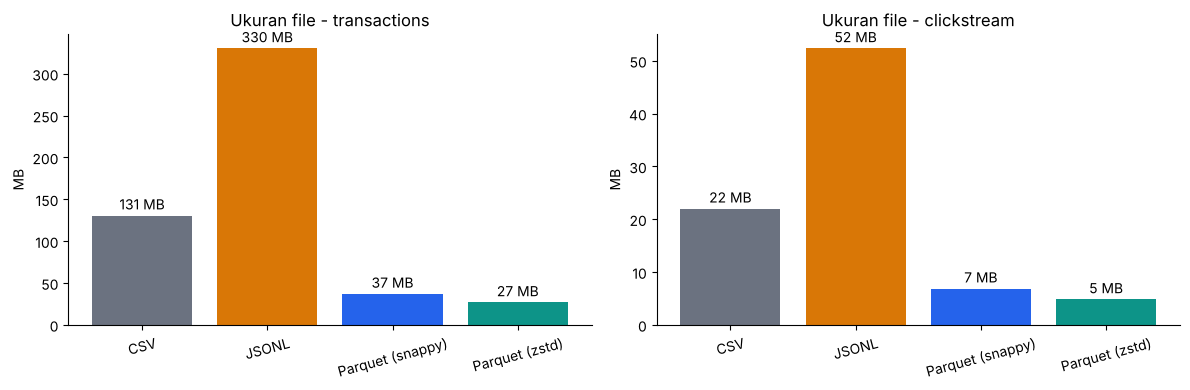

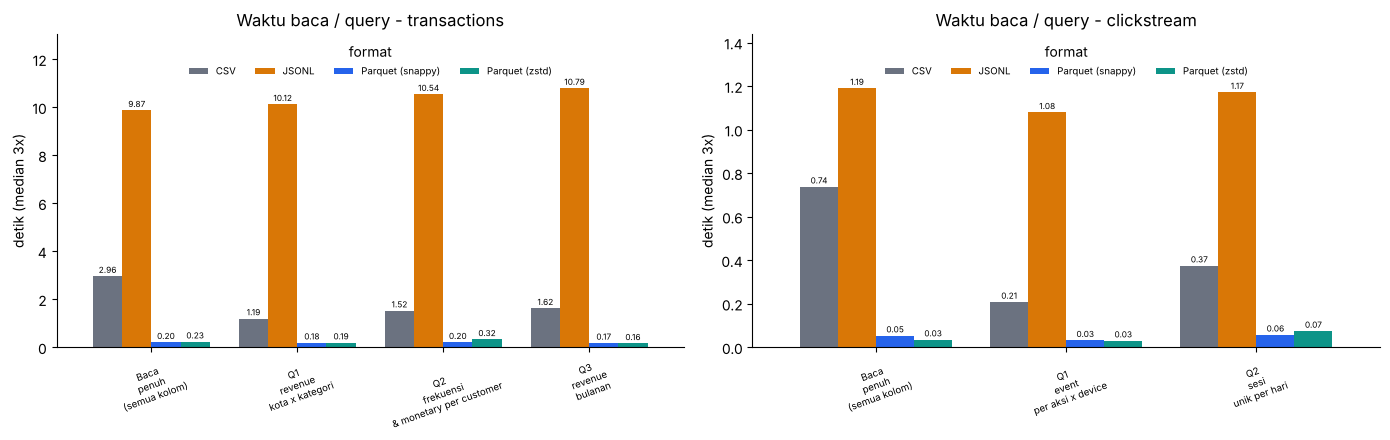

In [12]:
COLORS = ["#6b7280", "#d97706", "#2563eb", "#0d9488"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, ds in zip(axes, bench):
    d = size_df[size_df["dataset"] == ds]
    bars = ax.bar(d["format"], d["size_mb"], color=COLORS)
    ax.bar_label(bars, fmt="%.0f MB", padding=2)
    ax.set_title(f"Ukuran file - {ds}"); ax.set_ylabel("MB")
    ax.tick_params(axis="x", rotation=15); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(BENCH / "chart_file_size.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, ds in zip(axes, bench):
    t = (time_df[time_df["dataset"] == ds].pivot(index="workload", columns="format", values="seconds")[list(FORMATS)])
    t = t.loc[["Baca penuh (semua kolom)"] + list(WORKLOADS[ds])]
    t.plot.bar(ax=ax, color=COLORS, rot=20, width=0.8)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=6, padding=1)
    ax.set_title(f"Waktu baca / query - {ds}"); ax.set_ylabel("detik (median 3x)"); ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
    ax.legend(title="format", loc="upper center", ncol=4, fontsize=7, frameon=False)
    ax.set_xticklabels([x.get_text().replace(" ", "\n", 2) for x in ax.get_xticklabels()], fontsize=7)
plt.tight_layout(); plt.savefig(BENCH / "chart_query_time.png", dpi=150); plt.show()

## 6. Ringkasan hasil

In [13]:
lines = []
for ds in bench:
    s = size_df[size_df["dataset"] == ds].set_index("format")["size_mb"]
    t = time_df[time_df["dataset"] == ds].pivot(index="workload", columns="format", values="seconds")
    lines.append(f"[{ds}]")
    lines.append(f"  Ukuran: CSV {s['CSV']:.0f} MB | JSONL {s['JSONL']:.0f} MB | Parquet snappy {s['Parquet (snappy)']:.0f} MB "
                 f"| Parquet zstd {s['Parquet (zstd)']:.0f} MB")
    lines.append(f"  Parquet snappy lebih kecil {100 * (1 - s['Parquet (snappy)'] / s['CSV']):.0f}% dari CSV "
                 f"dan {100 * (1 - s['Parquet (snappy)'] / s['JSONL']):.0f}% dari JSONL")
    for wl, r in t.iterrows():
        lines.append(f"  {wl:<40} CSV/Parquet = {r['CSV'] / r['Parquet (snappy)']:5.1f}x | JSONL/Parquet = {r['JSONL'] / r['Parquet (snappy)']:5.1f}x")
print("\n".join(lines))

[transactions]
  Ukuran: CSV 131 MB | JSONL 330 MB | Parquet snappy 37 MB | Parquet zstd 27 MB
  Parquet snappy lebih kecil 72% dari CSV dan 89% dari JSONL
  Baca penuh (semua kolom)                 CSV/Parquet =  14.6x | JSONL/Parquet =  48.8x
  Q1 revenue kota x kategori               CSV/Parquet =   6.5x | JSONL/Parquet =  55.0x
  Q2 frekuensi & monetary per customer     CSV/Parquet =   7.5x | JSONL/Parquet =  52.1x
  Q3 revenue bulanan                       CSV/Parquet =   9.3x | JSONL/Parquet =  62.2x
[clickstream]
  Ukuran: CSV 22 MB | JSONL 52 MB | Parquet snappy 7 MB | Parquet zstd 5 MB
  Parquet snappy lebih kecil 69% dari CSV dan 87% dari JSONL
  Baca penuh (semua kolom)                 CSV/Parquet =  14.0x | JSONL/Parquet =  22.5x
  Q1 event per aksi x device               CSV/Parquet =   6.6x | JSONL/Parquet =  34.2x
  Q2 sesi unik per hari                    CSV/Parquet =   6.6x | JSONL/Parquet =  20.6x


## 7. Kesimpulan & rencana arsitektur PySpark (Milestone 2)

**Temuan utama** (angka lengkap pada tabel & grafik di atas):

* Parquet jauh lebih kecil dari CSV/JSONL karena penyimpanan *columnar* dengan *dictionary encoding* dan kompresi.
* Parquet unggul pada query agregasi karena hanya membaca kolom yang dibutuhkan (*column pruning*); CSV harus
  menelusuri seluruh baris teks, dan JSONL harus mem-parsing seluruh record.
* Parquet **zstd** memberi ukuran terkecil (+-21% dari CSV); waktu bacanya hampir setara snappy dan selisihnya
  bervariasi antar query (kadang sedikit lebih cepat, kadang sedikit lebih lambat), jauh lebih kecil dibanding
  selisih Parquet vs CSV/JSONL. Pilih zstd untuk penyimpanan, ukur ulang di lingkungan target untuk beban baca intensif.
* JSONL adalah format paling lambat dan paling besar karena nama kolom diulang di setiap record; cocok untuk *ingest* event semi-terstruktur, bukan untuk analitik berulang.

**Rencana PySpark - Milestone 2**

| Layer | Isi | Teknik |
|---|---|---|
| Bronze | data mentah -> Parquet | `spark.read.csv/json` dengan skema eksplisit (tanpa `inferSchema`), partisi per bulan |
| Silver | hasil cleansing | `dropDuplicates`, `na.drop`, `regexp_replace`/`create_map` untuk standardisasi kota, `broadcast join` dimensi `customers` (+-75 ribu baris) |
| Gold | tabel analitik | RFM (`ntile` window), cohort bulanan (`months_between`), funnel clickstream & sessionization (window function) |

Optimasi yang akan diuji: partisi `year_month`, `spark.sql.shuffle.partitions`, Adaptive Query Execution (AQE),
caching DataFrame hasil cleansing, dan perbandingan waktu pandas vs PySpark pada query yang sama.